In [1]:
import sys
from pathlib import Path
raiz = Path.cwd()
while not (raiz / "src").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.cuantizacion import (ajustar_cuantizador, transformar, reconstruir, calcular_error,
                              cuantizar_dataframe, reconstruir_dataframe, comparar_estadisticas,
                              guardar_modelos, cargar_modelos, ESTRATEGIAS, REPRESENTANTES)

BASE = raiz / "resultados" / "actividad3"
for d in ("graficos", "modelos"):
    (BASE / d).mkdir(parents=True, exist_ok=True)
COLS = ["edad", "ingresos", "altura"]

In [2]:
x = [10, 12, 15, 21, 24, 31, 35, 40]
m = ajustar_cuantizador(x, "uniforme", 4)
cod = transformar(x, m)
rec = reconstruir(cod, m)
print("límites:", m.limites)
print("códigos:", cod)
print("reconstruido:", rec)
err = calcular_error(x, rec)
print(err)
assert list(cod) == [0, 0, 0, 1, 1, 2, 3, 3]
assert abs(err["mae"] - 2.125) < 1e-12

límites: [10.  17.5 25.  32.5 40. ]
códigos: [0 0 0 1 1 2 3 3]
reconstruido: [13.75 13.75 13.75 21.25 21.25 28.75 36.25 36.25]
{'mae': 2.125, 'rmse': 2.4238399287081647, 'error_max': 3.75, 'n_validos': 8}


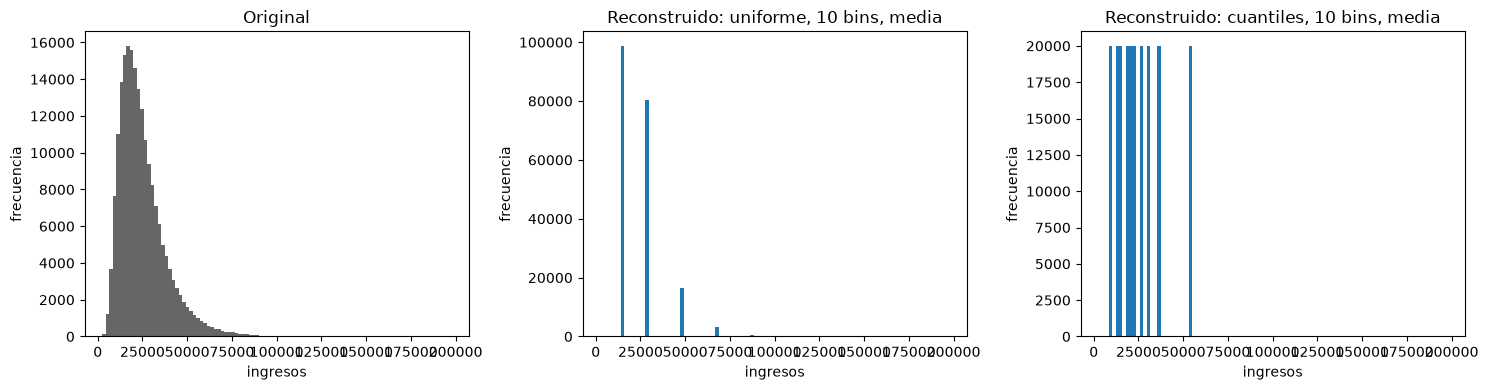

In [3]:
datos = pd.read_parquet(raiz / "data" / "dataset_1M.parquet", columns=COLS).sample(200_000, random_state=0)
ing = datos["ingresos"].to_numpy()
K = 10
bordes = np.linspace(ing.min(), ing.max(), 101)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(ing, bins=bordes, color="0.4")
ejes[0].set_title("Original")
for ax, estr in zip(ejes[1:], ESTRATEGIAS):
    mi = ajustar_cuantizador(ing, estr, K, columna="ingresos")
    ri = reconstruir(transformar(ing, mi), mi, "media")
    ax.hist(ri, bins=bordes)
    ax.set_title(f"Reconstruido: {estr}, {K} bins, media")
for ax in ejes:
    ax.set_xlabel("ingresos"); ax.set_ylabel("frecuencia")
fig.tight_layout()
fig.savefig(BASE / "graficos" / "demo_histograma_ingresos.png", dpi=130)

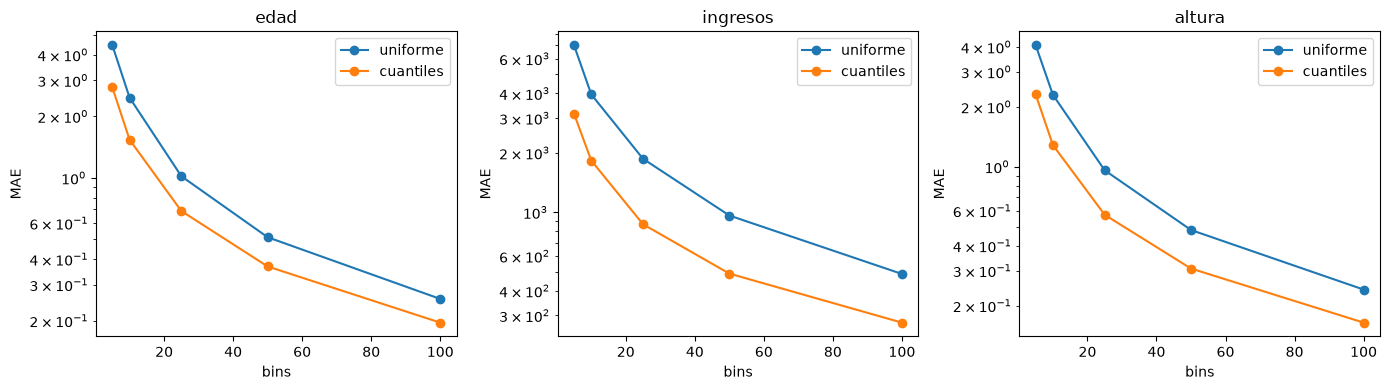

In [4]:
BINS = [5, 10, 25, 50, 100]
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(ejes, COLS):
    v = datos[c].to_numpy()
    for estr in ESTRATEGIAS:
        maes = []
        for k in BINS:
            mk = ajustar_cuantizador(v, estr, k)
            maes.append(calcular_error(v, reconstruir(transformar(v, mk), mk, "media"))["mae"])
        ax.plot(BINS, maes, marker="o", label=estr)
    ax.set_title(c); ax.set_xlabel("bins"); ax.set_ylabel("MAE")
    ax.set_yscale("log"); ax.legend()
fig.tight_layout()
fig.savefig(BASE / "graficos" / "demo_mae_vs_bins.png", dpi=130)

In [5]:
df_cod, modelos = cuantizar_dataframe(datos, COLS, "cuantiles", 10)
df_rec = reconstruir_dataframe(df_cod, modelos, "media")
est = comparar_estadisticas(datos[COLS], df_rec[COLS])
display(est["resumen"].round(4))
print("dif. máxima de correlación:", round(est["dif_correlacion_max"], 6))
print("memoria original (MB):", round(datos[COLS].memory_usage().sum() / 1e6, 2),
      "| códigos int16 (MB):", round(df_cod[COLS].memory_usage().sum() / 1e6, 2))

,columna,dif_media,dif_std,dif_q05,dif_q25,dif_q50,dif_q75,dif_q95
0,edad,-0.0,-0.2486,-1.3122,-0.044,0.0004,0.0461,1.3125
1,ingresos,0.0,-723.6535,-330.7431,-12.979,57.5182,81.3846,4084.7656
2,altura,-0.0,-0.2107,-1.1281,-0.037,-0.0042,0.0119,1.1614


dif. máxima de correlación: 0.001788
memoria original (MB): 6.4 | códigos int16 (MB): 2.8


In [6]:
ruta = BASE / "modelos" / "demo" / "cuantiles_10.json"
guardar_modelos(modelos, ruta)
cargados = cargar_modelos(ruta)
for c in COLS:
    assert np.array_equal(transformar(datos[c], modelos[c]), transformar(datos[c], cargados[c]))
print("OK: el modelo cargado produce los mismos códigos")
print(ruta.read_text(encoding="utf-8")[:400])

OK: el modelo cargado produce los mismos códigos
{
  "version": 1,
  "fecha": "2026-11-12T15:27:51",
  "modelos": {
    "edad": {
      "version": 1,
      "columna": "edad",
      "estrategia": "cuantiles",
      "n_bins_solicitado": 10,
      "n_bins_real": 10,
      "limites": [
        -15.163378197034078,
        24.58056693614154,
        29.87613056693004,
        33.69370689672019,
        36.96623810287611,
        39.98481411892524,
  


In [7]:
ruta = BASE / "modelos" / "demo" / "cuantiles_10.json"
guardar_modelos(modelos, ruta)
cargados = cargar_modelos(ruta)
for c in COLS:
    assert np.array_equal(transformar(datos[c], modelos[c]), transformar(datos[c], cargados[c]))
print("OK: el modelo cargado produce los mismos códigos")
print(ruta.read_text(encoding="utf-8")[:400])

OK: el modelo cargado produce los mismos códigos
{
  "version": 1,
  "fecha": "2026-11-12T15:27:57",
  "modelos": {
    "edad": {
      "version": 1,
      "columna": "edad",
      "estrategia": "cuantiles",
      "n_bins_solicitado": 10,
      "n_bins_real": 10,
      "limites": [
        -15.163378197034078,
        24.58056693614154,
        29.87613056693004,
        33.69370689672019,
        36.96623810287611,
        39.98481411892524,
  
